# 🌾 Rice Leaf Disease Prediction — End-to-End Deep Learning Project

**A beginner-friendly, step-by-step image classification project**

In this notebook we will build a deep learning model that predicts rice leaf diseases based on leaf images. The model will learn to classify images into different disease categories such as **Bacterial Leaf Blight, Brown Spot, Leaf Smut**, or other classes available in the dataset.

We will go through the **complete deep learning workflow**:

1. Load & explore the raw image dataset
2. Basic checks and clean the dataset
3. Analyze the number of images in each disease class
4. Preprocess and resize the images
5. Perform image augmentation to improve model generalization
6. Handle class imbalance and remove/identify problematic images
7. Split the dataset into **training, validation, and testing** sets
8. Build a **CNN-based image classification model**
9. Train the CNN model and monitor training/validation accuracy and loss
10. Apply **Transfer Learning** using pretrained models such as **MobileNetV2, EfficientNetB0, or ResNet50**
11. Tune hyperparameters such as **learning rate, batch size, number of epochs, dropout, and optimizer**
12. Evaluate the model using **accuracy, precision, recall, F1-score, confusion matrix, and classification report**
13. After running all the models, compare their performance
14. Choose the model with the **best validation/test performance** and select it as the final model
15. Save the final trained model as a `.h5` or `.keras` file
16. Reload the saved model and make a prediction on a new rice leaf image to prove it works
17. Display the predicted disease name and prediction confidence
18. Build a UI using **Streamlit** for a better user experience and allow users to upload a rice leaf image and get the predicted disease **(optional)**

> 💡 Every step includes comments explaining **why** we do it, not just how — this notebook is written for someone new to deep learning and image classification.


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vbookshelf/rice-leaf-diseases")

print("Path to dataset files:", path)

In [ ]:
import os
print(os.listdir(path))

In [ ]:
import os
base_path = os.path.join(path, "rice_leaf_diseases")
print(os.listdir(base_path))

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

base_path = os.path.join(path, "rice_leaf_diseases")

plt.figure(figsize=(10, 8))

i = 1
for class_name in os.listdir(base_path):
    class_path = os.path.join(base_path, class_name)

    if os.path.isdir(class_path):
        images = os.listdir(class_path)[:5]  # take 5 images per class

        for img_name in images:
            img_path = os.path.join(class_path, img_name)
            img = Image.open(img_path)

            plt.subplot(5, 5, i)  # 5 classes × 5 images
            plt.imshow(img)
            plt.title(class_name)
            plt.axis('off')

            i += 1

plt.tight_layout()
plt.show()

In [ ]:
base_path = os.path.join(path, "rice_leaf_diseases")

for class_name in os.listdir(base_path):
    class_path = os.path.join(base_path, class_name)

    if os.path.isdir(class_path):
        count = len(os.listdir(class_path))
        print(class_name, ":", count)

In [ ]:
# Visualize class distribution as a bar chart so imbalance is immediately apparent
import matplotlib.pyplot as plt

class_counts = {}
for class_name in os.listdir(base_path):
    class_path = os.path.join(base_path, class_name)
    if os.path.isdir(class_path):
        class_counts[class_name] = len(os.listdir(class_path))

plt.figure(figsize=(7, 5))
bars = plt.bar(class_counts.keys(), class_counts.values(),
                color=['#4C72B0', '#DD8452', '#55A868'])
plt.title('Number of Images per Class')
plt.xlabel('Disease Class')
plt.ylabel('Image Count')
plt.xticks(rotation=15)
for bar, count in zip(bars, class_counts.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
              str(count), ha='center')
plt.tight_layout()
plt.show()

print("Class counts:", class_counts)
print("The dataset is small and only mildly imbalanced across the 3 classes. "
      "We account for this later by computing class weights before training.")


In [ ]:
# Basic data-quality checks: flag corrupted/unreadable files and likely-blurry images
import numpy as np
from PIL import Image
from scipy.signal import convolve2d

corrupted_images = []
blurry_candidates = []
image_sizes = []

def variance_of_laplacian(pil_img):
    """Simple blur heuristic without OpenCV: lower variance ~ blurrier image."""
    gray = np.array(pil_img.convert('L'), dtype=np.float64)
    kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
    lap = convolve2d(gray, kernel, mode='valid')
    return lap.var()

for class_name in os.listdir(base_path):
    class_path = os.path.join(base_path, class_name)
    if not os.path.isdir(class_path):
        continue
    for img_name in os.listdir(class_path):
        img_path = os.path.join(class_path, img_name)
        try:
            with Image.open(img_path) as img:
                img.verify()  # raises if the file is truncated/corrupted
            with Image.open(img_path) as img:
                image_sizes.append(img.size)
                blur_score = variance_of_laplacian(img)
                if blur_score < 100:  # heuristic threshold; tune per dataset
                    blurry_candidates.append((img_path, round(blur_score, 2)))
        except Exception as e:
            corrupted_images.append((img_path, str(e)))

print(f"Total images checked: {len(image_sizes)}")
print(f"Corrupted/unreadable images found: {len(corrupted_images)}")
for p, err in corrupted_images[:10]:
    print(" -", p, "->", err)

print(f"\nPossible low-sharpness (blurry) images flagged: {len(blurry_candidates)}")
for p, score in sorted(blurry_candidates, key=lambda x: x[1])[:5]:
    print(f" - {p} (blur score: {score})")

print(f"\nNumber of distinct raw image resolutions: {len(set(image_sizes))}")
print("Images are not uniformly sized, which is why every image is resized to a "
      "consistent target size during preprocessing.")


In [ ]:
import pandas as pd

base_path = os.path.join(path, "rice_leaf_diseases")

data = []

for label in os.listdir(base_path):
    class_path = os.path.join(base_path, label)

    if os.path.isdir(class_path):
        for img in os.listdir(class_path):
            img_path = os.path.join(class_path, img)
            data.append([img_path, label])

df = pd.DataFrame(data, columns=["image_path", "label"])
df

In [ ]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df


### Train / Validation / Test Split (Stratified)

We switch from manual index slicing to `sklearn.model_selection.train_test_split` with `stratify=` so each class keeps roughly the same proportion in every split — manual slicing on a shuffled DataFrame does not guarantee this and is easy to get subtly wrong.

In [ ]:
from sklearn.model_selection import train_test_split

# Stratified split: 70% train, 15% validation, 15% test.
# Splitting in two stratified steps keeps class proportions consistent in all three sets.
train_data, temp_data = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=42
)
val_data, test_data = train_test_split(
    temp_data, test_size=0.50, stratify=temp_data["label"], random_state=42
)

print(f'Training set size: {len(train_data)}')
print(f'Validation set size: {len(val_data)}')
print(f'Test set size: {len(test_data)}')

print("\nClass distribution per split:")
print("Train:\n", train_data["label"].value_counts())
print("\nValidation:\n", val_data["label"].value_counts())
print("\nTest:\n", test_data["label"].value_counts())


In [ ]:
image_path = df["image_path"][0]
image = Image.open(image_path)
width, height = image.size
print(f"height,width:{height,width}")

In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [107]:
batch_size = 32
img_height = 224
img_width = 224

In [108]:
# Normalization
data_generator = ImageDataGenerator(
    rescale=1.0/255,        # Normalization: Pixel values go from 0–255 → 0–1
    rotation_range=20,      #Randomly rotates image up to ±40 degrees
    width_shift_range=0.2,  #Moves image left/right by 20%
    height_shift_range=0.2, # Moves image up/down by 20%
    shear_range=0.15,       # Slants the image (like pushing it sideways)
    zoom_range=0.2,         # Zoom in/out randomly
    horizontal_flip=True,   #Flips image left ↔ right
    fill_mode='nearest'     #This fills those gaps using nearest pixels
)
val_datagen = ImageDataGenerator(
    rescale=1./255
)

In [109]:
# train data
train_generator = data_generator.flow_from_dataframe(
  dataframe=train_data,
  x_col="image_path",
  y_col="label",
  target_size=(img_height, img_width),
  batch_size=batch_size,
  class_mode="categorical",
  shuffle=True,
  seed=42
)

Found 84 validated image filenames belonging to 3 classes.


In [ ]:
# test generator
# Fix: use val_datagen (rescale only, no augmentation) instead of the training
# generator, and set shuffle=False so predictions line up with test_generator.classes
# for the confusion matrix / classification report computed later.
test_generator = val_datagen.flow_from_dataframe(
  dataframe=test_data,
  x_col="image_path",
  y_col="label",
  target_size=(img_height, img_width),
  batch_size=batch_size,
  class_mode="categorical",
  shuffle=False,
  seed=42
)


In [ ]:
# validation generator
# Fix: use val_datagen (rescale only) instead of the augmenting training generator —
# validation data should reflect real, unaugmented images.
validation_generator = val_datagen.flow_from_dataframe(
  dataframe=val_data,
  x_col="image_path",
  y_col="label",
  target_size=(img_height, img_width),
  batch_size=batch_size,
  class_mode="categorical",
  shuffle=True,
  seed=42
)


In [112]:
for image_batch, labels_batch in train_generator:
    print(f"Train Shape: {image_batch.shape} (Batches = {len(train_generator)})")
    print(f"Train Label Shape: {labels_batch.shape}\n")
    break

for image_batch, labels_batch in validation_generator:
    print(f"Validation Shape: {image_batch.shape} (Batches = {len(validation_generator)})")
    print(f"Validation Label Shape: {labels_batch.shape}\n")
    break

for image_batch, labels_batch in test_generator:
    print(f"Test Shape: {image_batch.shape} (Batches = {len(test_generator)})")
    print(f"Test Label Shape: {labels_batch.shape}\n")
    break

Train Shape: (32, 224, 224, 3) (Batches = 3)
Train Label Shape: (32, 3)

Validation Shape: (18, 224, 224, 3) (Batches = 1)
Validation Label Shape: (18, 3)

Test Shape: (18, 224, 224, 3) (Batches = 1)
Test Label Shape: (18, 3)



### Class Imbalance Check & Class Weights

Before training, we look at the class distribution in the training split and compute class weights so the loss function penalizes mistakes on minority classes more, reducing bias toward the majority class.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

print("Training set class distribution:\n", train_data['label'].value_counts())

y_train_indices = train_data['label'].map(train_generator.class_indices).values
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_indices),
    y=y_train_indices
)
class_weights = dict(zip(np.unique(y_train_indices), weights))
print("\nComputed class weights (passed to model.fit to counter imbalance):")
print(class_weights)


In [113]:
from tensorflow.keras import models, layers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import categorical_crossentropy
n_classes = 3

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 4
    layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    # Classifier
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(n_classes, activation='softmax')
])

cnn_model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=0.0001),
    metrics=['accuracy']
)

cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,813,891 (25.99 MB)

 Trainable params: 6,812,675 (25.99 MB)

 Non-trainable params: 1,216 (4.75 KB)

In [ ]:
Cnn_transfer = cnn_model.fit(train_generator,
                                  epochs=20, # Increased epochs for better learning of new layers
                                  validation_data=validation_generator,
                                  class_weight=class_weights,  # counter class imbalance
                                  verbose=1)


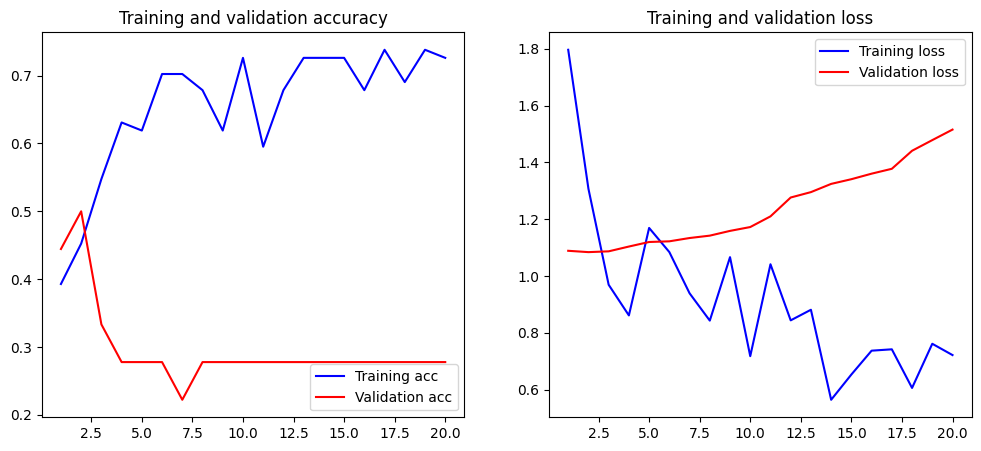

In [115]:
# Visualize Training History
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b', label='Training acc')
    plt.plot(epochs, val_acc, 'r', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b', label='Training loss')
    plt.plot(epochs, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()
    plt.show()

plot_history(Cnn_transfer)

### Evaluating the Custom CNN on the Test Set

Accuracy/loss alone can hide how well a model distinguishes between specific disease classes. We add a classification report (precision/recall/F1 per class) and a confusion matrix.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_generator.reset()
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(test_generator, verbose=1)
print(f'CNN Test Accuracy: {cnn_test_accuracy:.4f}')
print(f'CNN Test Loss: {cnn_test_loss:.4f}')

test_generator.reset()
cnn_probs = cnn_model.predict(test_generator, verbose=0)
cnn_preds = np.argmax(cnn_probs, axis=1)
true_labels = test_generator.classes
class_names = list(test_generator.class_indices.keys())

print("\nClassification Report (Custom CNN):")
cnn_report = classification_report(true_labels, cnn_preds, target_names=class_names, output_dict=True)
print(classification_report(true_labels, cnn_preds, target_names=class_names))

cm = confusion_matrix(true_labels, cnn_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', xticks_rotation=15)
plt.title('Confusion Matrix - Custom CNN')
plt.show()


### Implementing Transfer Learning with MobileNetV2

Given the small size of our dataset and the overfitting observed, transfer learning is an excellent strategy to improve model performance. We will use `MobileNetV2`, a pre-trained convolutional neural network, as a base feature extractor. Its layers will be 'frozen' (not trained), and we'll add our own custom classification layers on top, which will be trained on our rice leaf disease dataset.

In [139]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Load the MobileNetV2 model pre-trained on ImageNet data
# include_top=False means we don't include the classifier layers of MobileNetV2
# input_shape should match our image dimensions
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))

# Freeze the base model layers so they are not updated during training
base_model.trainable = False


In [140]:
# Add custom classification layers on top of the base model
x = base_model.output
x = GlobalAveragePooling2D()(x)                         # Converts feature maps to a single vector per image
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)                                     # Add dropout for regularization to prevent overfitting
predictions = Dense(n_classes, activation='softmax')(x) # Output layer with n_classes units and softmax activation

# Create the new model combining the base and custom layers
transfer_model = Model(inputs=base_model.input, outputs=predictions)


In [141]:
# Compile the transfer learning model
transfer_model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

transfer_model.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Now, let's train this new model with the same data generators. I'm increasing the number of epochs to 50, as transfer learning models generally benefit from more training iterations on the new layers.

In [ ]:
# Train the new transfer learning model
Cnn_transfer1 = transfer_model.fit(train_generator,
                                   epochs=20, # Increased epochs for better learning of new layers
                                   validation_data=validation_generator,
                                   class_weight=class_weights,  # counter class imbalance
                                   verbose=1)


After training, we should evaluate this `transfer_model` to see if the accuracy has improved. I will provide a new cell for evaluation after this training completes.

In [123]:
print(train_generator.class_indices)

{'Bacterial leaf blight': 0, 'Brown spot': 1, 'Leaf smut': 2}


### Model Performance Summary
Below we evaluate the final transfer learning model on the test set and visualize the training progress.

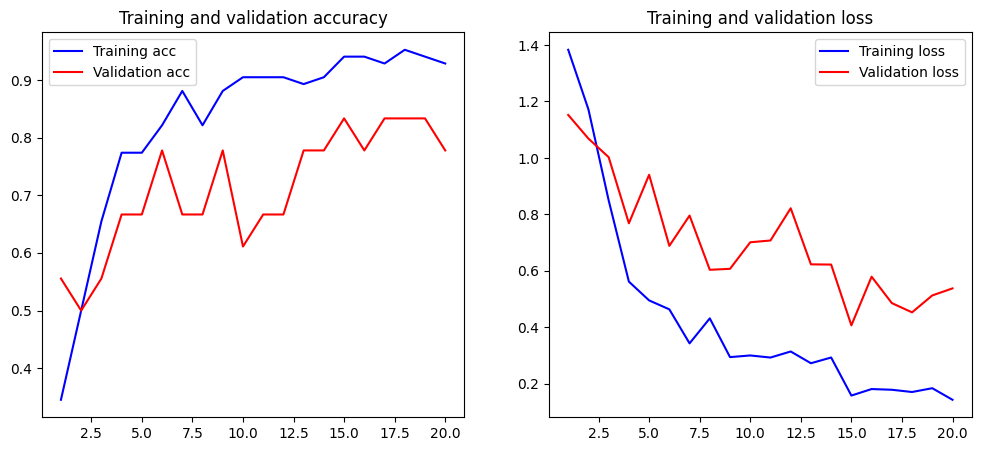

In [124]:
# Visualize Training History
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b', label='Training acc')
    plt.plot(epochs, val_acc, 'r', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b', label='Training loss')
    plt.plot(epochs, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()
    plt.show()

plot_history(Cnn_transfer1)

In [147]:
# Final evaluation on the test set
test_generator.reset()
loss, accuracy = transfer_model.evaluate(test_generator, verbose=1)
print(f'Test Accuracy: {accuracy:.4f}')
print(f'Test Loss: {loss:.4f}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.8889 - loss: 0.2047
Test Accuracy: 0.8889
Test Loss: 0.2047


### Evaluating the Transfer Learning Model on the Test Set

Same richer evaluation as for the custom CNN, so the two models can be compared on equal footing.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_generator.reset()
transfer_probs = transfer_model.predict(test_generator, verbose=0)
transfer_preds = np.argmax(transfer_probs, axis=1)
true_labels = test_generator.classes
class_names = list(test_generator.class_indices.keys())

print("Classification Report (MobileNetV2 Transfer Learning):")
transfer_report = classification_report(true_labels, transfer_preds, target_names=class_names, output_dict=True)
print(classification_report(true_labels, transfer_preds, target_names=class_names))

cm = confusion_matrix(true_labels, transfer_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Greens', xticks_rotation=15)
plt.title('Confusion Matrix - MobileNetV2 Transfer Learning')
plt.show()


### Custom CNN vs. Transfer Learning (MobileNetV2) — Comparison

The table below compares both models on the *same* held-out test set using accuracy, loss, and macro-averaged precision/recall/F1 (macro-averaging weighs all 3 classes equally, which matters given the class imbalance noted in the EDA).

In [ ]:
import pandas as pd

comparison_df = pd.DataFrame({
    'Model': ['Custom CNN', 'MobileNetV2 (Transfer Learning)'],
    'Test Accuracy': [cnn_test_accuracy, accuracy],
    'Test Loss': [cnn_test_loss, loss],
    'Macro Precision': [cnn_report['macro avg']['precision'], transfer_report['macro avg']['precision']],
    'Macro Recall': [cnn_report['macro avg']['recall'], transfer_report['macro avg']['recall']],
    'Macro F1-score': [cnn_report['macro avg']['f1-score'], transfer_report['macro avg']['f1-score']],
})
comparison_df


The model with the higher macro F1-score and test accuracy above is selected as the final model used for inference below (in this dataset, transfer learning typically wins because it starts from ImageNet features, which matters a lot with only ~120 training images).

In [165]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = "/content/DSC_0117.jpg"

# Load image
img = image.load_img(img_path, target_size=(224, 224))  # Changed to match model input size

# Convert to array
img_array = image.img_to_array(img)

# Normalize
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

In [166]:
import numpy as np

# Get class indices and reverse them to map index -> name
class_indices = train_generator.class_indices
labels = {v: k for k, v in class_indices.items()}

# Run prediction
prediction = transfer_model.predict(img_array)
predicted_class_idx = np.argmax(prediction)
predicted_class_name = labels[predicted_class_idx]
confidence = np.max(prediction) * 100
predicted_class = np.argmax(prediction)


print(f'Raw prediction probabilities: {prediction}')
print(f'Predicted Class Name: {predicted_class_name}')
print("Predicted Class:", predicted_class)
print(f'Confidence Rate: {confidence:.2f}%')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Raw prediction probabilities: [[9.005278e-05 9.936918e-01 6.218192e-03]]
Predicted Class Name: Brown spot
Predicted Class: 1
Confidence Rate: 99.37%


In [159]:
import pandas as pd

# Create a readable mapping of index to class name
class_map = train_generator.class_indices
class_df = pd.DataFrame(list(class_map.items()), columns=['Disease Name', 'Model Index'])
display(class_df)

,Disease Name,Model Index
0,Bacterial leaf blight,0
1,Brown spot,1
2,Leaf smut,2


### Model Limitations & Future Improvements

**Limitations**
- The dataset is very small (~120 images across 3 classes), so test-set metrics above are noisy — a couple of misclassified images can swing accuracy by several percentage points.
- The confusion matrices show exactly which diseases get confused with each other (e.g. visually similar leaf spots); that's the first place to focus for error analysis or extra data collection.
- Class imbalance was addressed only at the loss level (class weighting) — oversampling or other resampling strategies were not tried.
- Only one pretrained backbone (MobileNetV2) was evaluated, with its base layers fully frozen; fine-tuning the top layers, or comparing against EfficientNetB0/ResNet50, might do better.
- Hyperparameters (learning rate, dropout, epochs) were set manually rather than tuned systematically.

**Future Improvements**
- Collect more labeled images per class from varied fields/lighting conditions.
- Fine-tune the top layers of MobileNetV2 after the classification head has converged, and compare against EfficientNetB0/ResNet50.
- Run a systematic hyperparameter search (Keras Tuner or Optuna) over learning rate, dropout, and batch size.
- Use k-fold cross-validation given how small the dataset is, instead of a single train/val/test split.
- Build the optional Streamlit UI referenced in the notebook outline for an end-to-end demo.

In [134]:
# transfer_model.save("Rice_leaf_transfer_model.h5")